# CICIDS2017 Intrusion Detection with Explainable AI

This notebook trains a neural network to classify network flows as **BENIGN** or **ATTACK**. It then explains model predictions with LIME and SHAP.


In [1]:
# Import the libraries used in this notebook
import numpy as np
import pandas as pd
import sklearn
import tensorflow as tf
import xplique
import matplotlib.pyplot as plt
from pathlib import Path
from sklearn.model_selection import train_test_split
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import MinMaxScaler
from tensorflow import keras
from tensorflow.keras import layers
from sklearn.metrics import classification_report, confusion_matrix, average_precision_score
from sklearn.linear_model import Ridge
from xplique.attributions import Lime, KernelShap

# Check library versions
print("Pandas:", pd.__version__)
print("Scikit-learn:", sklearn.__version__)
print("TensorFlow:", tf.__version__)
print("Xplique: imported successfully")


Pandas: 3.0.6
Scikit-learn: 1.9.1
TensorFlow: 2.15.1
Xplique: imported successfully


## 1. Check the Dataset

In [2]:
# Check the dataset folder and count CSV files
DATA_DIR = Path("data/raw/MachineLearningCVE")

print("Current directory:", Path.cwd())
print("Dataset found:", DATA_DIR.exists())
print("CSV files:", len(list(DATA_DIR.glob("*.csv"))))


Current directory: /Users/arian/Documents/cicids2017-xai-ids
Dataset found: True
CSV files: 8


## 2. Load and Prepare the Data

In [3]:
# Load all CSV files and create binary labels: 0 = BENIGN, 1 = ATTACK
files = sorted(DATA_DIR.glob("*.csv"))
frames, labels = [], []

for file in files:
    data = pd.read_csv(file, low_memory=False)
    data.columns = data.columns.str.strip()

    # Convert labels to binary values
    labels.append(
        data.pop("Label").str.strip().ne("BENIGN").astype("int8")
    )

    # Convert features to numbers and mark invalid values as missing
    data = data.apply(pd.to_numeric, errors="coerce").astype("float32")
    data.replace([np.inf, -np.inf], np.nan, inplace=True)
    frames.append(data)

# Combine all files into one feature table and one label series
X = pd.concat(frames, ignore_index=True)
y = pd.concat(labels, ignore_index=True)

del frames, labels

print("Samples and features:", X.shape)
print("0 = BENIGN, 1 = ATTACK")
print(y.value_counts())


Samples and features: (2830743, 78)
0 = BENIGN, 1 = ATTACK
Label
0    2273097
1     557646
Name: count, dtype: int64


## 3. Split into Train, Validation, and Test Sets

In [4]:
# Stratified train/validation/test split
X_train, X_temp, y_train, y_temp = train_test_split(
    X, y, test_size=0.30, random_state=42, stratify=y
)

X_val, X_test, y_val, y_test = train_test_split(
    X_temp, y_temp, test_size=2/3, random_state=42, stratify=y_temp
)

del X, y, X_temp, y_temp

print("Train:", X_train.shape)
print("Validation:", X_val.shape)
print("Test:", X_test.shape)


Train: (1981520, 78)
Validation: (283074, 78)
Test: (566149, 78)


## 4. Handle Missing Values and Scale Features

In [5]:
# Median Imputation: fill missing values using training-set medians
imputer = SimpleImputer(strategy="median")

X_train = imputer.fit_transform(X_train)
X_val = imputer.transform(X_val)
X_test = imputer.transform(X_test)

# Min-Max Scaling: fit on training data, then transform validation and test data
scaler = MinMaxScaler()

X_train = scaler.fit_transform(X_train)
X_val = scaler.transform(X_val)
X_test = scaler.transform(X_test)

print("Train:", X_train.shape)
print("Validation:", X_val.shape)
print("Test:", X_test.shape)


Train: (1981520, 78)
Validation: (283074, 78)
Test: (566149, 78)


## 5. Build and Train the Neural Network

In [6]:
# Build a neural network for binary classification
model = keras.Sequential([
    layers.Input(shape=(78,)),
    layers.Dense(64, activation="relu"),
    layers.Dense(32, activation="relu"),
    layers.Dense(1, activation="sigmoid")  # Sigmoid output for the attack score
])

# Use binary cross-entropy loss and track precision, recall, and PR-AUC
model.compile(
    optimizer="adam",
    loss="binary_crossentropy",
    metrics=[
        keras.metrics.Precision(name="precision"),
        keras.metrics.Recall(name="recall"),
        keras.metrics.AUC(curve="PR", name="pr_auc")
    ]
)

# Train for five epochs
history = model.fit(
    X_train, y_train,
    validation_data=(X_val, y_val),
    epochs=5,
    batch_size=1024
)


Epoch 1/5
1936/1936 [==============================] - 2s 817us/step - loss: 0.1185 - precision: 0.8985 - recall: 0.8476 - pr_auc: 0.9537 - val_loss: 0.0769 - val_precision: 0.9182 - val_recall: 0.9316 - val_pr_auc: 0.9783
Epoch 2/5
1936/1936 [==============================] - 1s 736us/step - loss: 0.0700 - precision: 0.9212 - recall: 0.9270 - pr_auc: 0.9809 - val_loss: 0.0684 - val_precision: 0.8898 - val_recall: 0.9795 - val_pr_auc: 0.9836
Epoch 3/5
1936/1936 [==============================] - 1s 729us/step - loss: 0.0597 - precision: 0.9200 - recall: 0.9503 - pr_auc: 0.9850 - val_loss: 0.0557 - val_precision: 0.9187 - val_recall: 0.9614 - val_pr_auc: 0.9863
Epoch 4/5
1936/1936 [==============================] - 1s 716us/step - loss: 0.0529 - precision: 0.9187 - recall: 0.9658 - pr_auc: 0.9873 - val_loss: 0.0502 - val_precision: 0.9157 - val_recall: 0.9829 - val_pr_auc: 0.9893
Epoch 5/5
1936/1936 [==============================] - 2s 778us/step - loss: 0.0491 - precision: 0.9196 - re

## 6. Evaluate the Model

In [7]:
# Get attack scores for the test set
y_prob = model.predict(X_test, batch_size=1024).ravel()

# Classification threshold: scores >= 0.5 are predicted as ATTACK
y_pred = (y_prob >= 0.5).astype(int)

print(classification_report(
    y_test,
    y_pred,
    target_names=["BENIGN", "ATTACK"],
    digits=4
))

# Confusion matrix and False Positive Rate (FPR) = FP / (FP + TN)
cm = confusion_matrix(y_test, y_pred)
tn, fp, fn, tp = cm.ravel()

print("Confusion Matrix:")
print(cm)
print(f"False Positive Rate: {fp / (fp + tn):.4%}")
print(f"PR-AUC (Average Precision): {average_precision_score(y_test, y_prob):.4f}")


553/553 [==============================] - 0s 314us/step
              precision    recall  f1-score   support

      BENIGN     0.9938    0.9790    0.9864    454620
      ATTACK     0.9194    0.9753    0.9465    111529

    accuracy                         0.9783    566149
   macro avg     0.9566    0.9772    0.9664    566149
weighted avg     0.9792    0.9783    0.9785    566149

Confusion Matrix:
[[445080   9540]
 [  2755 108774]]
False Positive Rate: 2.0985%
PR-AUC (Average Precision): 0.9904


## 7. Local Explanation with Xplique LIME

Attack score: 1.0
Prediction: ATTACK


/opt/anaconda3/envs/cicids-ids/lib/python3.11/site-packages/xplique/attributions/lime.py:129: UserWarning: You set a number of perturbed samples per input >= 500 and batch_size is set to NoneThis mean that you will ask your model to handle more than 500 perturbed samples per input at once.This can lead to OOM issue. To avoid it you can set the batch_size argument.
  warnings.warn(


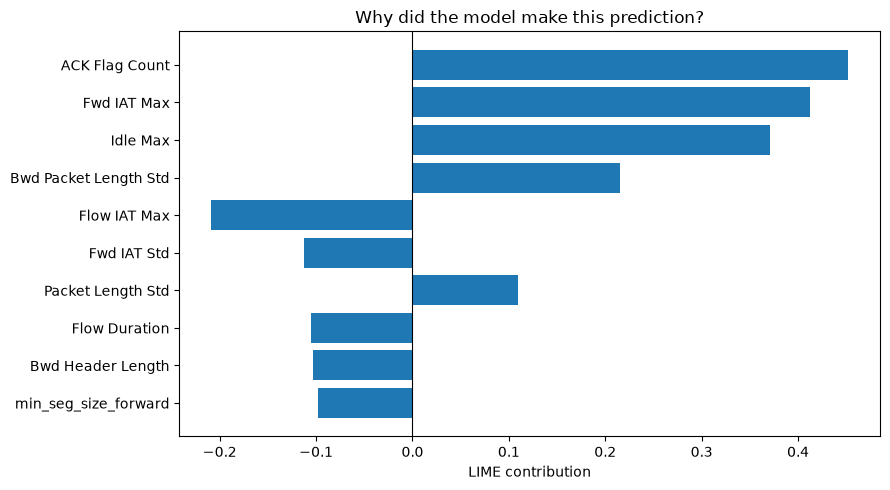

In [8]:
# Read feature names from the CSV header
feature_names = [
    c.strip()
    for c in pd.read_csv(files[0], nrows=0).columns
    if c.strip() != "Label"
]

# Select one test flow and get its attack score
sample = X_test[0:1]
score = float(model.predict(sample, verbose=0)[0, 0])

print("Attack score:", round(score, 4))
print("Prediction:", "ATTACK" if score >= 0.5 else "BENIGN")

# LIME kernel-width heuristic: 0.75 * sqrt(number of features)
explainer = Lime(
    model,
    nb_samples=500,
    kernel_width=0.75 * (X_train.shape[1] ** 0.5)
)

# Explain the model's single output (attack score)
explanation = explainer.explain(
    sample,
    targets=np.ones((1, 1), dtype=np.float32)
)

# Plot the 10 features with the largest absolute LIME contributions
scores = np.asarray(explanation).reshape(-1)
top = np.argsort(np.abs(scores))[-10:]
top = top[np.argsort(np.abs(scores[top]))]

plt.figure(figsize=(9, 5))
plt.barh(np.array(feature_names)[top], scores[top])
plt.axvline(0, color="black", linewidth=0.8)
plt.xlabel("LIME contribution")
plt.title("Why did the model make this prediction?")
plt.tight_layout()
plt.show()


In [9]:
# Check the true label of the selected test flow
actual = int(y_test.iloc[0])
print("Actual label:", "ATTACK" if actual == 1 else "BENIGN")


Actual label: ATTACK


## 8. Simplified LIME Implementation

This section implements a small educational version of LIME for one test flow. It creates perturbed samples, gets model predictions, gives nearby samples larger weights, and fits a locally weighted Ridge regression model. The explanation approximates the model locally; it does not prove the actual cause of an attack.


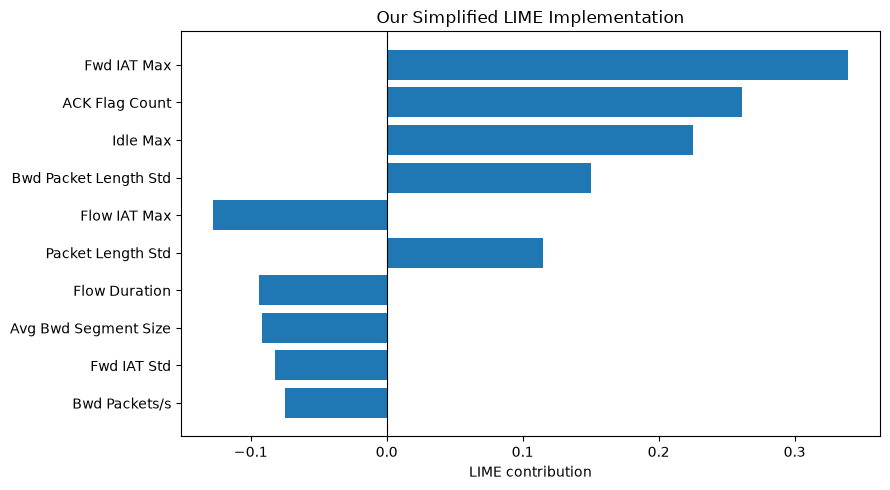

In [10]:
# Simplified LIME: explain one test flow
sample = X_test[0:1]

# Generate random background rows and binary feature masks
n_samples = 500
n_features = X_train.shape[1]
rng = np.random.default_rng(42)

background = X_train[
    rng.integers(0, len(X_train), size=n_samples)
]

# A mask value of 1 keeps the original feature; 0 replaces it
masks = rng.integers(
    0, 2, size=(n_samples, n_features)
).astype(np.float32)

# Keep the original sample as the first perturbed sample
masks[0] = 1.0

# Feature perturbation formula: keep original values or use background values
perturbed = masks * sample + (1 - masks) * background

# Get neural-network predictions for the perturbed samples
predictions = model.predict(
    perturbed, batch_size=128, verbose=0
).ravel()

# Euclidean distance in binary mask space
distances = np.sqrt(np.sum((1 - masks) ** 2, axis=1))

# LIME kernel-width heuristic: 0.75 * sqrt(number of features)
kernel_width = 0.75 * np.sqrt(n_features)

# Exponential kernel weights: closer samples receive larger weights
weights = np.exp(-(distances ** 2) / (kernel_width ** 2))

# Locally weighted Ridge regression
lime_model = Ridge(alpha=1.0)
lime_model.fit(masks, predictions, sample_weight=weights)

# Ridge coefficients represent local feature contributions
scores = lime_model.coef_

# Plot the 10 features with the largest absolute contributions
top = np.argsort(np.abs(scores))[-10:]
top = top[np.argsort(np.abs(scores[top]))]

plt.figure(figsize=(9, 5))
plt.barh(np.array(feature_names)[top], scores[top])
plt.axvline(0, color="black", linewidth=0.8)
plt.xlabel("LIME contribution")
plt.title("Our Simplified LIME Implementation")
plt.tight_layout()
plt.show()


## 9. Local SHAP

Local SHAP explains one test flow. It assigns a SHAP value to each feature for the selected flow.


In [11]:
# Create the KernelSHAP explainer
shap_explainer = KernelShap(
    model,
    nb_samples=200,
    batch_size=64
)

# Explain the model's single output (attack score) for this flow
shap_explanation = shap_explainer.explain(
    sample,
    targets=np.ones((1, 1), dtype=np.float32)
)

# Store the 78 feature SHAP values in a one-dimensional array
shap_scores = np.asarray(shap_explanation).reshape(-1)

print("Number of SHAP values:", len(shap_scores))


Number of SHAP values: 78


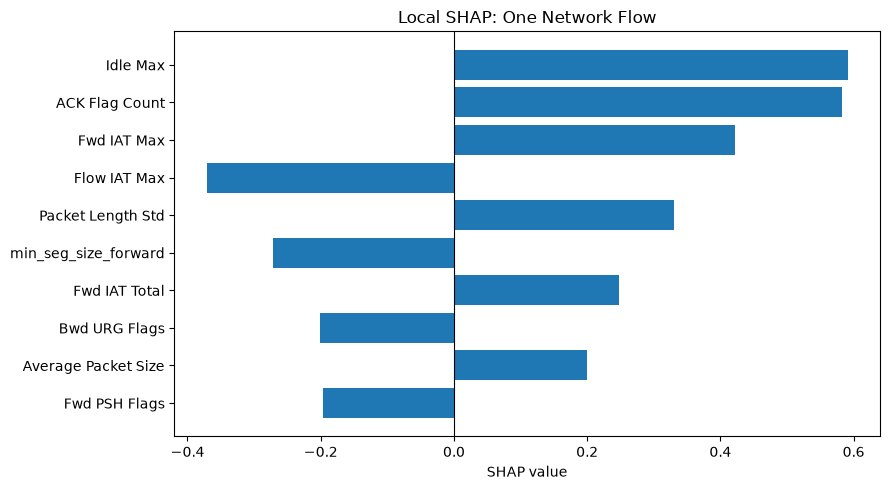

In [12]:
# Plot the 10 features with the largest absolute SHAP values
top_local = np.argsort(np.abs(shap_scores))[-10:]
top_local = top_local[np.argsort(np.abs(shap_scores[top_local]))]

plt.figure(figsize=(9, 5))
plt.barh(np.array(feature_names)[top_local], shap_scores[top_local])
plt.axvline(0, color="black", linewidth=0.8)
plt.xlabel("SHAP value")
plt.title("Local SHAP: One Network Flow")
plt.tight_layout()
plt.show()


## 10. Global SHAP

Global SHAP summarizes feature importance across multiple flows. Here, we use 100 randomly selected test flows to keep the computation manageable.


In [13]:
# Select 100 random test flows
rng = np.random.default_rng(42)
indices = rng.choice(len(X_test), size=100, replace=False)
X_global = X_test[indices]

# Select the model's single output (attack score) for each flow
targets_global = np.ones((len(X_global), 1), dtype=np.float32)

# Compute SHAP values for the selected flows
global_shap = shap_explainer.explain(
    X_global,
    targets=targets_global
)

global_shap = np.asarray(global_shap)
print("SHAP result shape:", global_shap.shape)


SHAP result shape: (100, 78)


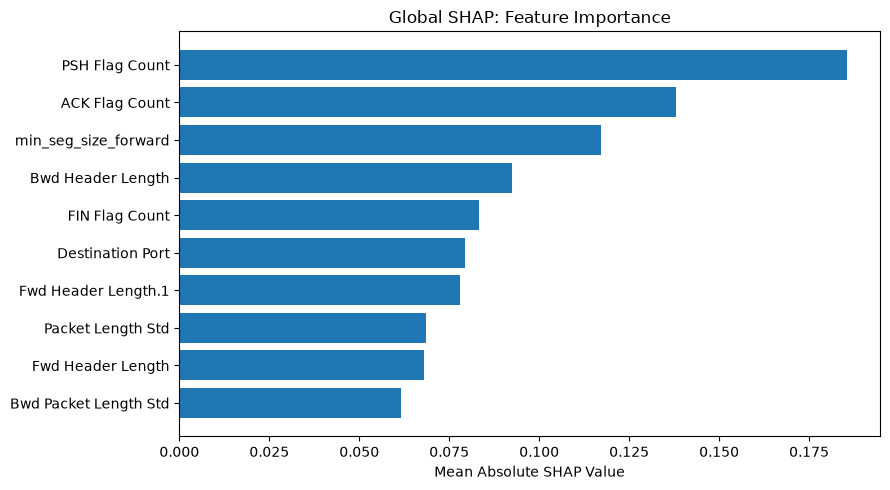

In [14]:
# Mean Absolute SHAP Value: average absolute SHAP value across samples
global_importance = np.mean(np.abs(global_shap), axis=0)

# Select the 10 features with the highest average importance
top_global = np.argsort(global_importance)[-10:]
top_global = top_global[
    np.argsort(global_importance[top_global])
]

# Plot global feature importance
plt.figure(figsize=(9, 5))
plt.barh(
    np.array(feature_names)[top_global],
    global_importance[top_global]
)
plt.xlabel("Mean Absolute SHAP Value")
plt.title("Global SHAP: Feature Importance")
plt.tight_layout()
plt.show()
